# P09 — Só células T CD4: limpeza e novo UMAP

**Por que este passo.**
- Os clusters 7, 10 e 11 do P08 têm muito menos genes e UMIs que os demais.
- Os clusters 14, 15, 17 e 18 são de outras linhagens.
- O atlas de Yasumizu et al. 2024, usado como régua, só tem células CD4⁺.

Por isso, antes de anotar e comparar, toda a análise passa a usar só as células T CD4 de boa
qualidade.

Este notebook:

1. define e justifica a remoção **por cluster do P08**: baixa qualidade (7, 10 e 11) e
   contaminantes (14, 15, 17 e 18). Nenhuma célula sai pelo Azimuth (decisão do usuário; a
   seção 2 mostra que o Azimuth chama de CD8 células que são CD4 citotóxicas);
2. refaz HVG, ComBat, PCA, grafo e UMAP **só nas CD4** (a receita do ComBat escolhido no P07);
3. mostra a UMAP nova e o painel de marcadores pela coluna `anotacao` (sem varrer resoluções do
   Leiden nem criar clusters novos).

**Rótulos.** Usa só a coluna `anotacao` da 1ª rodada (`analises_previas/P09_anotacao`),
transferida por `cell_key`.

**Rodada anterior.** P09–P17 estão em `raw/analises_previas/`. As saídas estão em
`resultsReseq/{figures,tables}/analises_previas/` e `dataReseq/analises_previas/`.

**Limite de inferência.** 7 pacientes e 14 bibliotecas; MB e NP têm um paciente cada.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import time
import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from IPython.display import display

from functions import config, fmt as F, io, pipeline as pl, plotting
from functions import benchmark as bm
from functions import composicao as CP
from functions import composicao_sc as CS
from functions import forest_composicao as FR
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)
sc.settings.verbosity = 0

NB = "P09_cd4_limpo"
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK
SEED = 0

# clusters do P08 (leiden_final, resolução 1,0) removidos inteiros; justificativa nas seções 1 e 2
BAIXA_QUALIDADE = ["7", "10", "11"]
CONTAMINANTE = ["14", "15", "17", "18"]

In [2]:
caminho = io.data_path("P05_integracao", "reseq_raw_integrado", "h5ad")
adata = ad.read_h5ad(caminho)
keys = adata.obs["cell_key"].astype(str).to_numpy()
delta = ad.read_h5ad(io.data_path("P07_benchmark_integracao", "integracao_escolhida", "h5ad"))
assert (delta.obs["cell_key"].astype(str).to_numpy() == keys).all()
INTEG = dict(delta.uns["integracao"])
clus = pd.read_parquet(io.data_path("P08_clusterizacao", "clusters", "parquet")).set_index("cell_key").reindex(keys)
prev = pd.read_parquet(io.data_path("analises_previas/P09_anotacao", "anotacao", "parquet")).set_index("cell_key").reindex(keys)
az = bm.azimuth_labels(adata.obs).set_index("cell_key").reindex(keys)

obs = adata.obs
obs["leiden_P08"] = clus["leiden_final"].astype(str).to_numpy()
obs["azimuth_grupo"] = az[bm.LABEL].astype(object).to_numpy()      # só diagnóstico (seção 2), não filtra
for c in ("anotacao", "grupo", "atlas_L1", "atlas_L2"):
    obs[c] = prev[c].astype(object).to_numpy()
N = adata.n_obs
SYM = pd.Index(adata.var["gene_symbol"].astype(str))
print(f"{caminho.name}: {F.n(N)} células × {F.n(adata.n_vars)} genes · {plotting.N_DESIGN}")
print(f"integração do P07: {INTEG['metodo']} ({INTEG['execucao']})")
assert (pd.Series(obs["azimuth_grupo"]).astype(str).to_numpy() == prev["azimuth_grupo"].astype(str).to_numpy()).all()

reseq_raw_integrado__v2.h5ad: 35.247 células × 26.053 genes · 14 bibliotecas · 7 pacientes
integração do P07: ComBat (combat_esc)


## 1. Baixa qualidade: clusters 7, 10 e 11

QC por cluster do P08: medianas de UMIs, genes e %MT, a fração de células abaixo do padrão de
profundidade (`baixa_profundidade`, do P03) e a fração vinda das bibliotecas estimuladas.

In [3]:
CL = sorted(obs["leiden_P08"].unique(), key=int)
g = obs.groupby("leiden_P08", observed=True)
qc = pd.DataFrame({
    "células": g.size(),
    "UMIs (mediana)": g["total_counts"].median(),
    "genes (mediana)": g["n_genes_by_counts"].median(),
    "%MT (mediana)": g["pct_counts_mt"].median(),
    "baixa profundidade": g["baixa_profundidade"].agg(lambda s: pd.Series(s).astype(str).str.lower().isin(["true", "1"]).mean()),
    "fração ML": g["estimulo"].agg(lambda s: (s.astype(str) == "estimulado").mean()),
}).reindex(CL)
qc["genes / mediana dos demais"] = qc["genes (mediana)"] / qc.loc[~qc.index.isin(BAIXA_QUALIDADE + CONTAMINANTE), "genes (mediana)"].median()
qc["remoção"] = np.select([qc.index.isin(BAIXA_QUALIDADE), qc.index.isin(CONTAMINANTE)],
                          ["baixa qualidade", "contaminante"], "")
io.save_table(qc, NB, "qc_por_cluster_P08", description="QC por cluster do P08 e a remoção decidida")
display(qc.round(3))

,células,UMIs (mediana),genes (mediana),%MT (mediana),baixa profundidade,fração ML,genes / mediana dos demais,remoção
leiden_P08,,,,,,,,
0,6940,11016.5,3294.0,2.836,0.000,0.572,1.085,
1,4968,9746.0,3056.5,3.501,0.000,0.500,1.007,
2,4415,8343.0,2422.0,3.565,0.001,0.589,0.798,
3,3086,10881.0,3322.5,2.839,0.000,0.575,1.095,
4,2798,6302.0,1949.5,2.710,0.001,0.804,0.642,
5,2696,6811.0,1892.5,2.798,0.004,0.499,0.624,
6,2159,11742.0,3507.0,3.358,0.000,0.321,1.156,
7,1855,1353.0,748.0,3.363,0.102,0.839,0.246,baixa qualidade
8,1733,7991.0,2782.0,2.936,0.001,0.580,0.917,


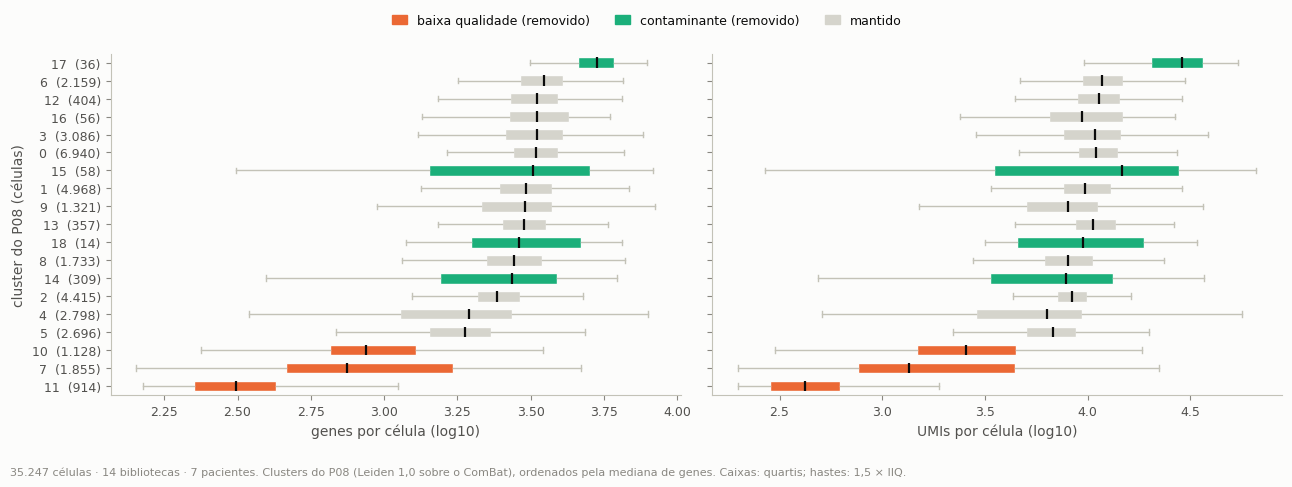

In [4]:
COR_REM = {"baixa qualidade": plotting.CATEGORICAL[1], "contaminante": plotting.CATEGORICAL[2]}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
ordem = qc.sort_values("genes (mediana)").index.tolist()
for ax, col, rot in zip(axes, ["n_genes_by_counts", "total_counts"], ["genes por célula", "UMIs por célula"]):
    dados = [np.log10(obs.loc[obs["leiden_P08"] == c, col].to_numpy(float)) for c in ordem]
    bp = ax.boxplot(dados, vert=False, widths=0.6, patch_artist=True, showfliers=False,
                    medianprops=dict(color=INK["primary"], lw=1.6), whiskerprops=dict(color=INK["axis"]),
                    capprops=dict(color=INK["axis"]))
    for patch, c in zip(bp["boxes"], ordem):
        patch.set_facecolor(COR_REM.get(qc.loc[c, "remoção"], plotting.CONTEXT))
        patch.set_edgecolor(INK["surface"])
    ax.set_yticks(range(1, len(ordem) + 1))
    ax.set_yticklabels([f"{c}  ({F.n(qc.loc[c, 'células'])})" for c in ordem])
    ax.set_xlabel(f"{rot} (log10)")
    ax.grid(axis="y", visible=False)
axes[0].set_ylabel("cluster do P08 (células)")
fig.legend(handles=[mpl.patches.Patch(color=COR_REM["baixa qualidade"], label="baixa qualidade (removido)"),
                    mpl.patches.Patch(color=COR_REM["contaminante"], label="contaminante (removido)"),
                    mpl.patches.Patch(color=plotting.CONTEXT, label="mantido")],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.0))
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Clusters do P08 (Leiden 1,0 sobre o ComBat), "
                   "ordenados pela mediana de genes. Caixas: quartis; hastes: 1,5 × IIQ.", y=0.0)
fig.tight_layout(rect=(0, 0.03, 1, 0.93))
plotting.savefig(fig, NB, "qc_por_cluster", description="Genes e UMIs por célula em cada cluster do P08",
                 data=qc.reset_index(), data_index=False)
plt.show()

## 2. Contaminantes, e por que o Azimuth não entra no filtro

**Por cluster.** Fração de células com pelo menos uma contagem de marcadores de linhagem, em
cada cluster do P08.

**Célula a célula.** O Azimuth do Cell Ranger chama de CD8, NK, B ou mieloide células espalhadas
pelos clusters CD4. A segunda tabela confere esses rótulos com a expressão dos marcadores, nos
clusters mantidos. Ela serve só de diagnóstico: o filtro não usa o Azimuth.

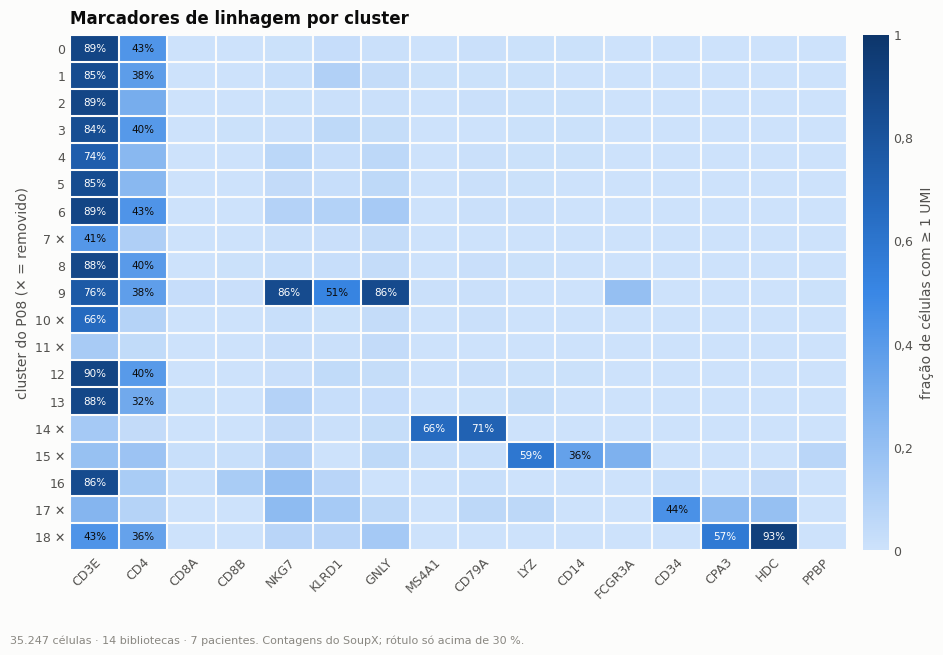

In [5]:
MARC = ["CD3E", "CD4", "CD8A", "CD8B", "NKG7", "KLRD1", "GNLY", "MS4A1", "CD79A", "LYZ", "CD14", "FCGR3A",
        "CD34", "CPA3", "HDC", "PPBP"]
MARC_AZ = ["CD3E", "CD3D", "CD4", "CD8A", "CD8B", "NKG7", "GNLY", "GZMB", "KLRF1", "NCAM1", "MS4A1", "LYZ"]
GENES = list(dict.fromkeys(MARC + MARC_AZ))
cols_m = [int(np.flatnonzero(SYM == m)[0]) for m in GENES]
Xm = sp.csr_matrix(adata.layers["counts"][:, cols_m])
expr = pd.DataFrame((Xm > 0).toarray(), columns=GENES, index=obs.index)
frac_cl = expr[MARC].groupby(obs["leiden_P08"].to_numpy()).mean().reindex(CL)
frac_cl.index = [f"{c}{' ✕' if c in BAIXA_QUALIDADE + CONTAMINANTE else ''}" for c in CL]
fig, ax = plt.subplots(figsize=(9.5, 6.4))
plotting.heatmap(ax, frac_cl, vmin=0, vmax=1, cbar_label="fração de células com ≥ 1 UMI", annotate_above=0.3,
                 fmt=".0%", xrotation=45)
ax.set_ylabel("cluster do P08 (✕ = removido)")
ax.set_title("Marcadores de linhagem por cluster", loc="left")
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Contagens do SoupX; rótulo só acima de 30 %.", y=0.0)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plotting.savefig(fig, NB, "marcadores_linhagem", description="Fração de células que expressam marcadores de linhagem, por cluster do P08",
                 data=frac_cl)
plt.show()

In [6]:
mant_cl = ~obs["leiden_P08"].isin(BAIXA_QUALIDADE + CONTAMINANTE).to_numpy()
azg = pd.Series(obs["azimuth_grupo"]).fillna("sem rótulo (fora do Cell Ranger)").astype(str).to_numpy()
conf = expr.loc[mant_cl, MARC_AZ].groupby(azg[mant_cl]).mean()
conf.insert(0, "células", pd.Series(azg[mant_cl]).value_counts())
io.save_table(conf, NB, "azimuth_x_marcadores", description="Nos clusters mantidos: fração que expressa cada marcador, por grupo do Azimuth")
display(conf.round(3))
cito = (obs["anotacao"].astype(str) == "CD4 citotóxica (Temra)").to_numpy()
az_cd8 = azg == "CD8 e T não convencional"
fino = prev["azimuth_fino"].astype(str).to_numpy()
print(f"CD4 citotóxica (Temra) da 1ª rodada: {F.n(cito.sum())} células; o Azimuth chama "
      f"{F.n((cito & az_cd8).sum())} de 'CD8 e T não convencional' ({F.pct((cito & az_cd8).sum() / cito.sum(), 0)}), "
      f"{F.n((cito & (fino == 'GZMB CD8 T cell')).sum())} delas de 'GZMB CD8 T cell'")
m = mant_cl & az_cd8
print(f"nessas 'CD8' do Azimuth: CD4 em {F.pct(expr.loc[m, 'CD4'].mean(), 0)} das células (demais CD4: "
      f"{F.pct(expr.loc[mant_cl & (azg != 'CD8 e T não convencional'), 'CD4'].mean(), 0)}); CD8A ou CD8B em "
      f"{F.pct((expr.loc[m, 'CD8A'] | expr.loc[m, 'CD8B']).mean(), 1)}")

,células,CD3E,CD3D,CD4,CD8A,CD8B,NKG7,GNLY,GZMB,KLRF1,NCAM1,MS4A1,LYZ
B e plasmócito,2,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000,0.000,0.000,0.000,0.000
CD4 memória,3977,0.868,0.904,0.356,0.002,0.003,0.096,0.115,0.038,0.007,0.004,0.006,0.008
CD4 naive,22571,0.868,0.885,0.365,0.002,0.003,0.015,0.029,0.008,0.010,0.004,0.002,0.005
CD8 e T não convencional,852,0.851,0.925,0.419,0.036,0.027,0.961,0.891,0.811,0.124,0.028,0.005,0.004
NK e ILC,76,0.224,0.132,0.053,0.053,0.000,0.803,0.882,0.724,0.618,0.355,0.000,0.013
Treg,2766,0.784,0.862,0.319,0.001,0.006,0.043,0.040,0.027,0.003,0.004,0.001,0.007
mieloide,1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
sem rótulo (fora do Cell Ranger),688,0.750,0.769,0.326,0.007,0.006,0.221,0.218,0.145,0.038,0.007,0.003,0.013


CD4 citotóxica (Temra) da 1ª rodada: 1.321 células; o Azimuth chama 811 de 'CD8 e T não convencional' (61%), 737 delas de 'GZMB CD8 T cell'
nessas 'CD8' do Azimuth: CD4 em 42% das células (demais CD4: 36%); CD8A ou CD8B em 4,8%


**Leitura.** As células que o Azimuth chama de "CD8 e T não convencional" (quase todas
"GZMB CD8 T cell") estão no cluster CD4 citotóxica. Elas expressam CD4 na mesma frequência das
outras CD4 e quase não expressam CD8A/CD8B. São **CD4 citotóxicas**: a referência do Azimuth não
tem essa classe e as joga em CD8.

Um filtro pelo Azimuth tiraria cerca de 2/3 das CD4 citotóxicas, e por isso nenhuma célula sai
por ele. As poucas células com perfil de NK (CD3 baixo, KLRF1, NCAM1) ficam nos clusters
mantidos. A reanotação confere se os clusters novos as separam.

## 3. O filtro

Saem os clusters inteiros: baixa qualidade (7, 10 e 11) e contaminantes (14, 15, 17 e 18).

In [7]:
motivo = np.select([obs["leiden_P08"].isin(BAIXA_QUALIDADE).to_numpy(), obs["leiden_P08"].isin(CONTAMINANTE).to_numpy()],
                   ["baixa qualidade", "contaminante"], "mantida")
obs["motivo_remocao"] = motivo
# os clusters removidos são exatamente os que a 1ª rodada anotou como baixa qualidade e contaminante
assert set(obs.loc[obs["leiden_P08"].isin(BAIXA_QUALIDADE), "grupo"]) == {"baixa qualidade"}
assert set(obs.loc[obs["leiden_P08"].isin(CONTAMINANTE), "grupo"]) == {"contaminante"}
assert (obs["grupo"].isin(["baixa qualidade", "contaminante"]).to_numpy() == ~mant_cl).all()

tab = pd.crosstab(obs["library_id"].astype(str), obs["motivo_remocao"]).reindex(LIBS)
tab = tab[["mantida", "baixa qualidade", "contaminante"]]
tab["total"] = tab.sum(axis=1)
tab["% removida"] = 100 * (1 - tab["mantida"] / tab["total"])
tab.loc["total"] = tab.sum()
tab.loc["total", "% removida"] = 100 * (1 - tab.loc["total", "mantida"] / tab.loc["total", "total"])
io.save_table(tab, NB, "celulas_removidas", description="Células mantidas e removidas por motivo e biblioteca")
filtro = pd.DataFrame({"cell_key": keys, "library_id": obs["library_id"].astype(str).to_numpy(), "motivo": motivo})
io.save_data(filtro, NB, "filtro_celulas", description="Motivo de remoção (ou 'mantida') de cada célula do objeto principal; só por cluster do P08")
display(tab.round(1))
N_CD4 = int((motivo == "mantida").sum())
print(f"mantidas {F.n(N_CD4)} de {F.n(N)} ({F.pct(N_CD4 / N, 1)}); "
      + "; ".join(f"{k}: {F.n(v)}" for k, v in pd.Series(motivo).value_counts().drop("mantida").items()))

[io] inalterado, não regravado: filtro_celulas__v2.parquet


motivo_remocao,mantida,baixa qualidade,contaminante,total,% removida
library_id,,,,,
CTH92_NS,805.0,51.0,4.0,860.0,6.4
CTH92_ML,1231.0,325.0,13.0,1569.0,21.5
CTH94_NS,5288.0,293.0,88.0,5669.0,6.7
CTH94_ML,507.0,23.0,5.0,535.0,5.2
CTH97_NS,1409.0,126.0,10.0,1545.0,8.8
CTH97_ML,2853.0,1703.0,102.0,4658.0,38.8
PB20_NS,558.0,43.0,25.0,626.0,10.9
PB20_ML,740.0,63.0,38.0,841.0,12.0
PB21_NS,3485.0,296.0,9.0,3790.0,8.0


mantidas 30.933 de 35.247 (87,8%); baixa qualidade: 3.897; contaminante: 417


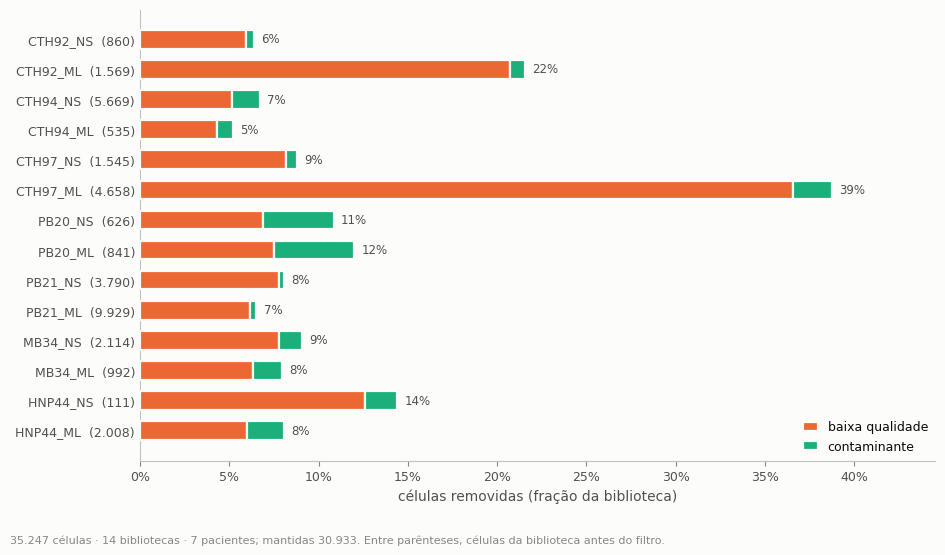

In [8]:
frac_rem = tab.drop(index="total")[list(COR_REM)].div(tab.drop(index="total")["total"], axis=0)
fig, ax = plt.subplots(figsize=(9.5, 5.4))
y = np.arange(len(LIBS))[::-1]
left = np.zeros(len(LIBS))
for col, cor in COR_REM.items():
    v = frac_rem[col].to_numpy()
    ax.barh(y, v, left=left, color=cor, height=0.62, edgecolor=INK["surface"], lw=1.6, label=col, zorder=3)
    left += v
for yi, tot in zip(y, left):
    ax.text(tot + 0.004, yi, F.pct(tot, 0), va="center", fontsize=8.5, color=INK["secondary"])
ax.set_yticks(y)
ax.set_yticklabels([f"{l}  ({F.n(tab.loc[l, 'total'])})" for l in LIBS])
plotting.percent(ax, "x")
ax.set_xlim(0, float(left.max()) * 1.15)
ax.set_xlabel("células removidas (fração da biblioteca)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right", frameon=False)
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}; mantidas {F.n(N_CD4)}. "
                   "Entre parênteses, células da biblioteca antes do filtro.", y=0.0)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plotting.savefig(fig, NB, "celulas_removidas", description="Fração removida de cada biblioteca, por motivo",
                 data=frac_rem.rename_axis("library_id").reset_index(), data_index=False)
plt.show()

## 4. Reprocessamento só nas CD4

A receita do ComBat escalado, o método escolhido pelo benchmark do P07, aplicada às células
mantidas:

1. HVG `seurat_v3` por biblioteca (2.000 genes), calculadas nas contagens do SoupX. Entram os
   genes com contagem em pelo menos 3 células do conjunto novo;
2. lognorm (10⁴, log1p) e escala (`max_value = 10`);
3. ComBat por biblioteca;
4. PCA de 50 componentes sobre a matriz corrigida;
5. grafo de 15 vizinhos nas 50 componentes (como no `benchmark._graph`) e UMAP.

In [9]:
t0 = time.time()
cd4 = adata[motivo == "mantida"].copy()
del adata
cd4.obs["library_id"] = pd.Categorical(cd4.obs["library_id"].astype(str), sorted(LIBS))
n_cel = np.asarray((sp.csr_matrix(cd4.layers["counts"]) > 0).sum(axis=0)).ravel()
b = cd4[:, n_cel >= config.GLOBAL_MIN_CELLS].copy()
b.var_names = pd.Index(ad.utils.make_index_unique(pd.Index(b.var["gene_symbol"].astype(str))))
hvg = pl.select_hvg(b)
HVG = hvg.index[hvg["highly_variable"]]
hvg_p05 = pd.Index(ad.utils.make_index_unique(SYM))[cd4.var["highly_variable"].to_numpy()]
novos, sairam = HVG.difference(hvg_p05), hvg_p05.difference(HVG)
print(f"{F.n(b.n_vars)} genes com ≥ {config.GLOBAL_MIN_CELLS} células; HVG: {len(HVG)}; "
      f"em comum com o P05: {len(HVG.intersection(hvg_p05))}; novas {len(novos)}; saíram {len(sairam)}")
io.save_table(pd.DataFrame({"gene": list(sairam) + list(novos),
                            "mudança": ["saiu (só HVG no P05)"] * len(sairam) + ["entrou (só HVG agora)"] * len(novos)}),
              NB, "hvg_mudancas", index=False, description="HVG que saíram e que entraram em relação ao P05")
print("saíram (amostra):", ", ".join(list(sairam[:30])))
print("entraram (amostra):", ", ".join(list(novos[:30])))

ln_all = pl.lognorm(b.layers["counts"])
pre = ad.AnnData(X=ln_all[:, b.var_names.get_indexer(HVG)].toarray(), obs=b.obs[["library_id"]].copy(),
                 var=pd.DataFrame(index=HVG))
sc.pp.scale(pre, max_value=10)
sc.pp.combat(pre, key="library_id")
sc.tl.pca(pre, n_comps=config.N_PCS, random_state=config.RANDOM_STATE)
novo = ad.AnnData(obs=b.obs[["cell_key", "library_id"]].copy())
novo.obsm["X_emb"] = np.asarray(pre.obsm["X_pca"], np.float32)
sc.pp.neighbors(novo, n_neighbors=bm.N_NEIGHBORS, use_rep="X_emb", random_state=SEED)
sc.tl.umap(novo, random_state=SEED)
print(f"reprocessamento em {time.time() - t0:.0f} s; {F.n(novo.n_obs)} células")

26.046 genes com ≥ 3 células; HVG: 2000; em comum com o P05: 1386; novas 614; saíram 614
saíram (amostra): ABR, ACOD1, ACSM3, ADA, ADAM7-AS1, ADGRE2, ADORA2A, AIM2, AIRN, ALDH1A2, ALDH2, ALOX5, AMOT, ANGPT1, ANKMY2, ANKRD12, ANKRD22, ANKRD31, ANPEP, ANXA5, AP1S3, APOA1, APOBEC3A, AQP9, ARFGAP3, ARHGAP24, ARHGAP31-AS1, ARHGAP39, ARHGEF10, ARHGEF10L
entraram (amostra): ABCB1, ABCB5, ABCC4, ABCG2, ABL1, ACVR2A, ADAM22, ADAMTS18, ADCY9, ADGRB3, ADGRG2, AFF2, AFG1L, AGPAT4, AHCYL2, AHI1, AIG1, AK9, ALPK3, ANKRD27, ANKRD6, ANKS3, ANO10, ANTXR1, APBA1, APOBEC3G, ARHGEF12, ARHGEF28, ARL15, ARL6


reprocessamento em 66 s; 30.933 células


## 5. Integração antes × depois, nas mesmas células

**Antes:** o grafo e o embedding do P07, calculados com as 35.247 células e aqui restritos às
células mantidas. **Depois:** os do reprocessamento só nas CD4.

Medidas:
- vizinhos da mesma biblioteca;
- iLISI (número efetivo de bibliotecas ou pacientes entre os vizinhos);
- separação NS × ML dentro do paciente (0 = misturadas, 1 = separadas; o estímulo deve continuar
  separado);
- correlação das 5 primeiras dimensões com a profundidade.

In [10]:
idx = np.flatnonzero(motivo == "mantida")
G_antes = sp.csr_matrix(delta.obsp["connectivities"])[idx][:, idx]
emb_antes = np.asarray(delta.obsm["X_emb"])[idx]
um_antes = np.asarray(delta.obsm["X_umap"])[idx]
lib = cd4.obs["library_id"].astype(str).to_numpy()
pat = cd4.obs["patient"].astype(str).to_numpy()
umis = cd4.obs["total_counts"].to_numpy()
ANTES, DEPOIS = "antes (ComBat do P07, restrito)", "depois (ComBat só nas CD4)"
linhas = []
for nome, G, E in [(ANTES, G_antes, emb_antes), (DEPOIS, novo.obsp["connectivities"], novo.obsm["X_emb"])]:
    k = pl.knn_library_mixing(G, lib)
    kp = pl.knn_library_mixing(G, pat)
    sep = pl.within_patient_separation(G, lib, pat)
    rho = pl.depth_correlation(E, umis)
    linhas.append({"grafo": nome,
                   "vizinhos da mesma biblioteca (mediana)": float(k["frac_vizinhos_mesma_biblioteca"].median()),
                   "iLISI de bibliotecas (mediana)": float(k["ilisi"].median()),
                   "iLISI de pacientes (mediana)": float(kp["ilisi"].median()),
                   "separação NS × ML no paciente (mediana)": float(sep["separacao"].median()),
                   "|ρ| profundidade, maior das 5 primeiras dims": float(np.max(np.abs(rho)))})
mistura = pd.DataFrame(linhas).set_index("grafo")
mistura["iLISI de bibliotecas, mistura perfeita"] = pl.expected_ilisi(lib)
io.save_table(mistura, NB, "integracao_antes_depois", description="Mistura, estímulo preservado e profundidade antes e depois do reprocessamento")
display(mistura.round(3))

,vizinhos da mesma biblioteca (mediana),iLISI de bibliotecas (mediana),iLISI de pacientes (mediana),separação NS × ML no paciente (mediana),"|ρ| profundidade, maior das 5 primeiras dims","iLISI de bibliotecas, mistura perfeita"
grafo,,,,,,
"antes (ComBat do P07, restrito)",0.350,3.462,2.588,0.338,0.414,6.483
depois (ComBat só nas CD4),0.333,3.521,2.604,0.316,0.333,6.483


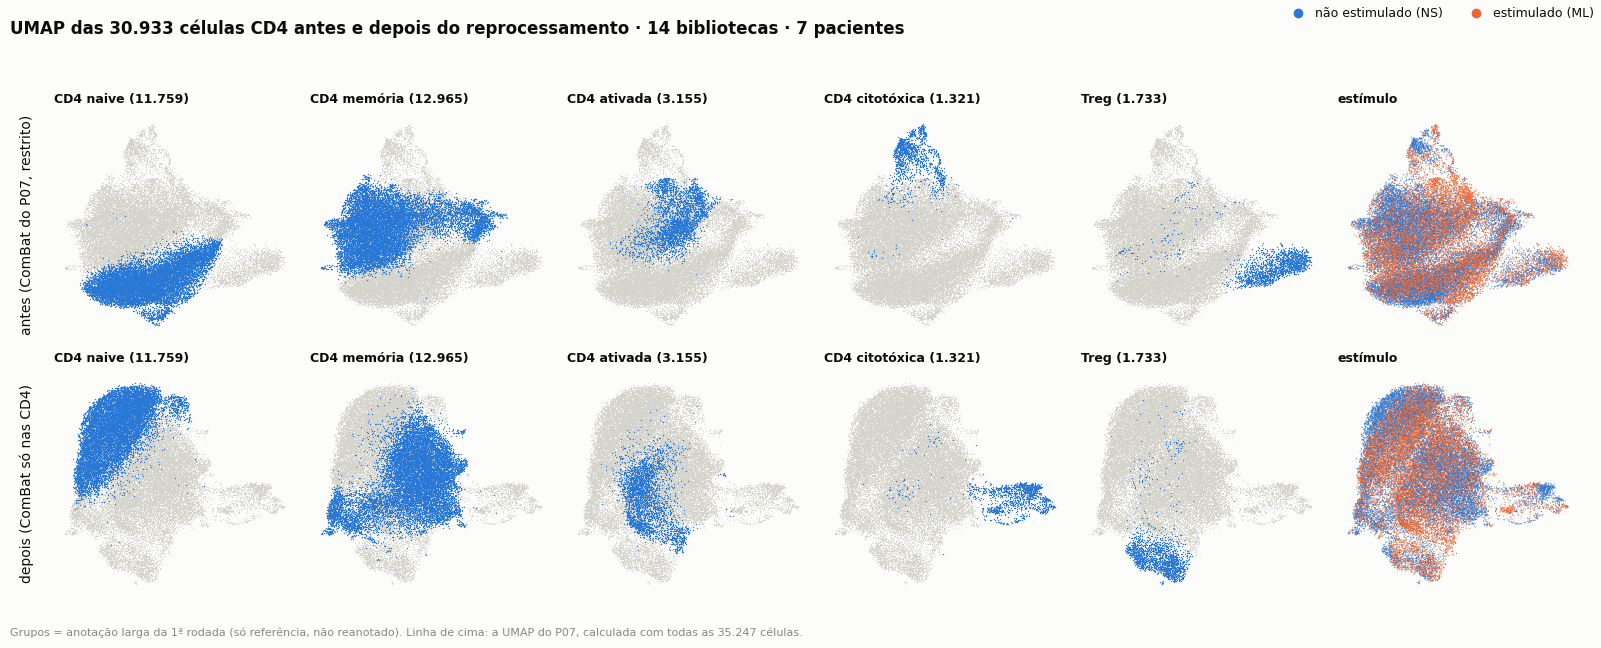

In [11]:
GRUPOS = ["CD4 naive", "CD4 memória", "CD4 ativada", "CD4 citotóxica", "Treg"]
grp = cd4.obs["grupo"].astype(str).to_numpy()
est_ = cd4.obs["estimulo"].astype(str).to_numpy()
COR_EST_UMAP = {"nao estimulado": plotting.STIMULATION_COLORS["nao_estimulado"],
                "estimulado": plotting.STIMULATION_COLORS["estimulado"]}
rng = np.random.default_rng(SEED)
ordem_pts = rng.permutation(len(idx))
fig, axes = plt.subplots(2, 6, figsize=(16, 6.2))
for r, (nome, um) in enumerate([(ANTES, um_antes), (DEPOIS, novo.obsm["X_umap"])]):
    for j, gr in enumerate(GRUPOS):
        ax = axes[r, j]
        m = grp == gr
        ax.scatter(um[:, 0], um[:, 1], s=0.6, c=plotting.CONTEXT, lw=0, rasterized=True)
        ax.scatter(um[m, 0], um[m, 1], s=0.9, c=plotting.ACCENT, lw=0, rasterized=True)
        ax.set_title(f"{gr} ({F.n(m.sum())})", fontsize=9)
        plotting._umap_axes(ax)
    ax = axes[r, 5]
    ax.scatter(um[ordem_pts, 0], um[ordem_pts, 1], s=0.6, lw=0, rasterized=True,
               c=[COR_EST_UMAP[e] for e in est_[ordem_pts]])
    ax.set_title("estímulo", fontsize=9)
    plotting._umap_axes(ax)
    axes[r, 0].text(-0.08, 0.5, nome, transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right",
                    fontsize=10, color=INK["primary"])
fig.legend(handles=[mpl.lines.Line2D([], [], marker="o", ls="", color=COR_EST_UMAP["nao estimulado"], label="não estimulado (NS)"),
                    mpl.lines.Line2D([], [], marker="o", ls="", color=COR_EST_UMAP["estimulado"], label="estimulado (ML)")],
           loc="upper right", ncol=2, frameon=False)
fig.suptitle(f"UMAP das {F.n(N_CD4)} células CD4 antes e depois do reprocessamento · {plotting.N_DESIGN}",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plotting.note(fig, "Grupos = anotação larga da 1ª rodada (só referência, não reanotado). Linha de cima: a UMAP do P07, "
                   "calculada com todas as 35.247 células.", y=0.0)
fig.tight_layout(rect=(0.01, 0.03, 1, 0.94))
plotting.savefig(fig, NB, "umap_antes_depois", description="UMAP antes (P07, restrita) e depois (só CD4), por grupo e estímulo",
                 data=pd.DataFrame({"cell_key": cd4.obs["cell_key"].astype(str).to_numpy(), "grupo": grp, "estimulo": est_,
                                    "umap1_antes": um_antes[:, 0], "umap2_antes": um_antes[:, 1],
                                    "umap1_depois": novo.obsm["X_umap"][:, 0], "umap2_depois": novo.obsm["X_umap"][:, 1]}),
                 data_index=False)
plt.show()

## 6. UMAP pela anotação

A UMAP nova (ComBat só nas CD4), colorida pela coluna `anotacao` (anotação por marcadores da 1ª
rodada, transferida por `cell_key`) e pelo estímulo.

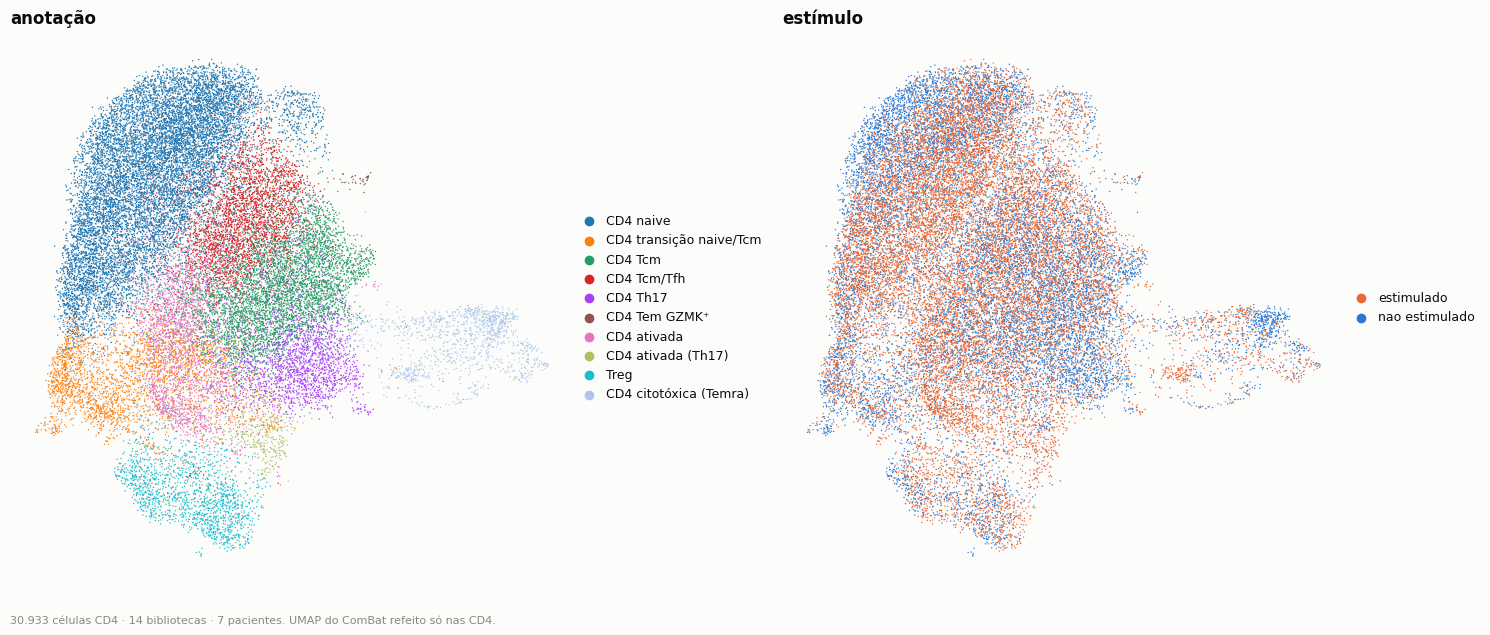

In [12]:
from functions import anotacao as an

ORD = [l for l in an.LABEL_ORDER if l in set(cd4.obs["anotacao"].astype(str))]
novo.obs["anotacao"] = pd.Categorical(cd4.obs["anotacao"].astype(str).to_numpy(), categories=ORD)
novo.obs["estimulo"] = pd.Categorical(cd4.obs["estimulo"].astype(str).to_numpy())
novo.uns["estimulo_colors"] = [plotting.STIMULATION_COLORS["estimulado"] if c == "estimulado"
                               else plotting.STIMULATION_COLORS["nao_estimulado"] for c in novo.obs["estimulo"].cat.categories]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
sc.pl.umap(novo, color="anotacao", ax=axes[0], show=False, frameon=False, size=4, title="anotação")
sc.pl.umap(novo, color="estimulo", ax=axes[1], show=False, frameon=False, size=4, title="estímulo")
plotting.note(fig, f"{F.n(N_CD4)} células CD4 · {plotting.N_DESIGN}. UMAP do ComBat refeito só nas CD4.", y=0.0)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plotting.savefig(fig, NB, "umap_anotacao", description="UMAP das CD4 (ComBat só nas CD4) pela anotação e pelo estímulo",
                 data=pd.DataFrame({"cell_key": novo.obs["cell_key"].astype(str).to_numpy(),
                                    "anotacao": novo.obs["anotacao"].astype(str).to_numpy(),
                                    "estimulo": novo.obs["estimulo"].astype(str).to_numpy(),
                                    "umap1": novo.obsm["X_umap"][:, 0], "umap2": novo.obsm["X_umap"][:, 1]}),
                 data_index=False)
plt.show()

## 7. Painel de marcadores por tipo (dotplot)

O painel canônico do P09 da 1ª rodada (`functions/anotacao.PANEL`), agora por tipo da `anotacao`
e só nas CD4. Tamanho do ponto = % de células que detectam o gene (≥ 1 UMI, contagens do
SoupX); cor = média da lognorm, escalonada por gene entre os tipos (0–1).

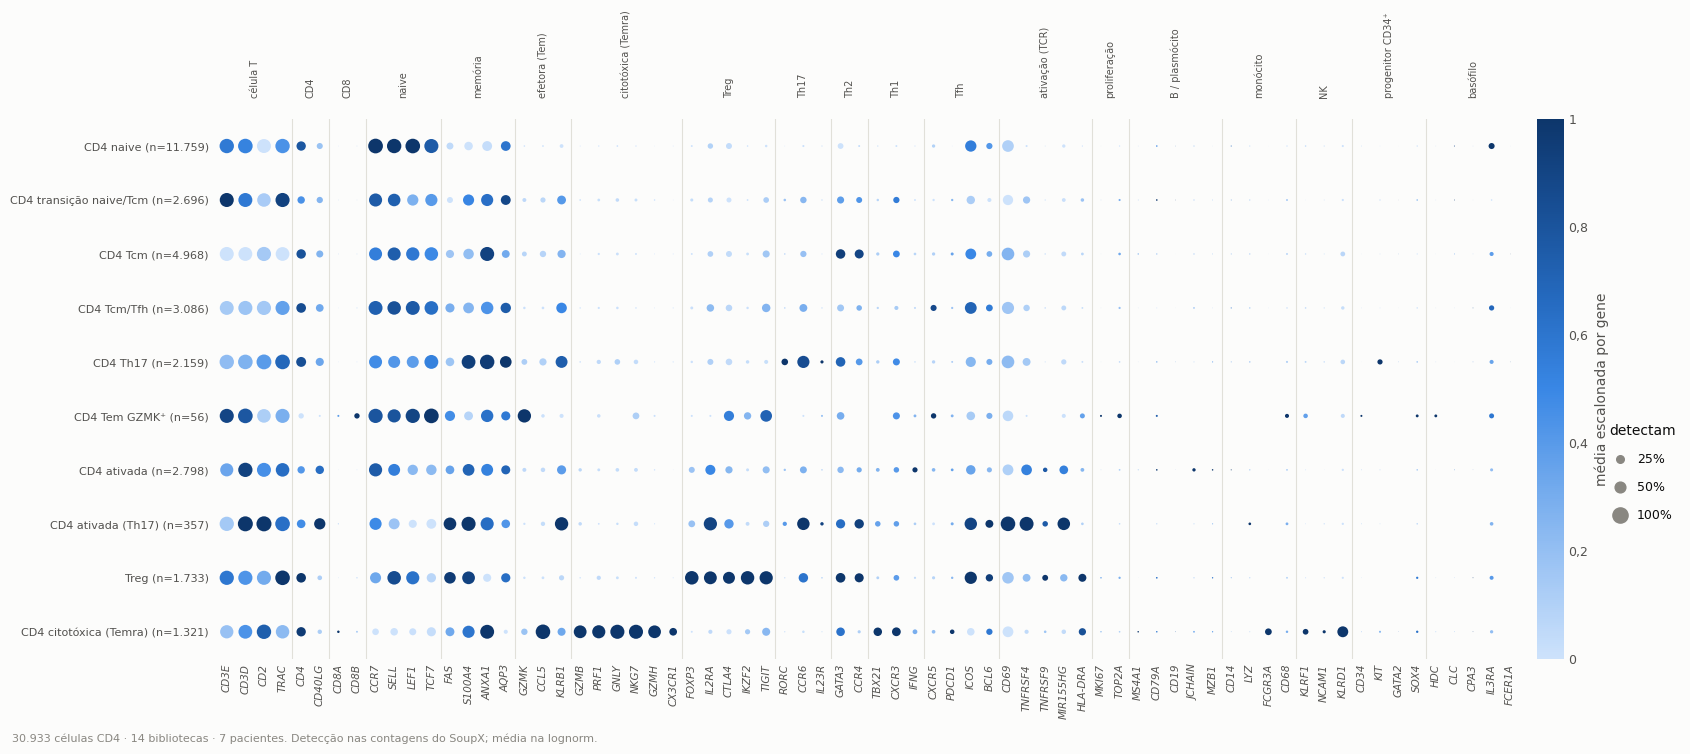

In [13]:
a_sym = ad.AnnData(X=ln_all, obs=cd4.obs[["anotacao"]].copy(), var=pd.DataFrame(index=b.var_names.str.replace("_", "-")))
a_sym.layers["counts"] = b.layers["counts"]
genes = [g for g in an.panel_genes() if g in a_sym.var_names]
frac, mean = an.dot_stats(a_sym, a_sym.obs["anotacao"], genes)
n_t = a_sym.obs["anotacao"].astype(str).value_counts()
grupos_col = [(t, len([g for g in gs if g in a_sym.var_names])) for t, (gs, _) in an.PANEL.items()]
fig, ax = plt.subplots(figsize=(17, 0.42 * len(ORD) + 3.2))
sc_ = an.dotplot(ax, frac, mean, rows=ORD, cols=genes, groups_of_cols=grupos_col)
ax.set_yticklabels([f"{t} (n={F.n(n_t[t])})" for t in ORD])
cb = fig.colorbar(sc_, ax=ax, fraction=0.02, pad=0.01)
cb.set_label("média escalonada por gene")
plotting._style_colorbar(cb)
for v in (0.25, 0.5, 1.0):
    ax.scatter([], [], s=v * 120, c=INK["muted"], label=F.pct(v, 0))
ax.legend(title="detectam", loc="upper left", bbox_to_anchor=(1.06, 0.45), frameon=False, labelspacing=1.2)
plotting.note(fig, f"{F.n(N_CD4)} células CD4 · {plotting.N_DESIGN}. Detecção nas contagens do SoupX; média na lognorm.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "painel_por_tipo", description="Marcadores canônicos por tipo da anotação, só CD4",
                 data=(frac * 100).round(1).reindex(ORD).rename_axis("anotacao").reset_index(), data_index=False)
plt.show()
del a_sym

## 9. O objeto

Delta das células mantidas, unido ao objeto principal por `cell_key`. Contém:
- o embedding do ComBat só nas CD4 (50 dims), a UMAP e o grafo de 15 vizinhos;
- a `anotacao` (1ª rodada), sem colunas de Leiden;
- as HVG em `uns`.

O motivo de remoção de cada uma das 35.247 células fica em `filtro_celulas.parquet`.

In [14]:
out = ad.AnnData(X=sp.csr_matrix((cd4.n_obs, 0), dtype=np.float32), obs=pd.DataFrame({"cell_key": cd4.obs["cell_key"].astype(str).to_numpy(),
                                   "library_id": cd4.obs["library_id"].astype(str).to_numpy()}, index=cd4.obs_names))
out.obs["anotacao"] = cd4.obs["anotacao"].astype(str).to_numpy()
out.obsm["X_emb_combat"] = novo.obsm["X_emb"]
out.obsm["X_umap"] = np.asarray(novo.obsm["X_umap"], np.float32)
out.obsp["connectivities"] = novo.obsp["connectivities"]
out.obsp["distances"] = novo.obsp["distances"]
out.uns["cd4_limpo"] = {"hvg": list(map(str, HVG)),
                        "baixa_qualidade_P08": BAIXA_QUALIDADE, "contaminante_P08": CONTAMINANTE,
                        "filtro": "só por cluster do P08; nenhuma célula removida pelo Azimuth",
                        "receita": "seurat_v3 por biblioteca (2.000) → lognorm → scale(10) → ComBat(library_id) → PCA 50 → 15 vizinhos → UMAP"}
p = io.save_data(out, NB, "cd4_limpo", description="Delta das CD4 limpas: ComBat só nas CD4, UMAP, grafo e anotação")
print(p)

[io] conteúdo mudou — nova versão: cd4_limpo__v2.h5ad (anterior preservada)


/mnt/SATA/singleCellTaru/dataReseq/P09_cd4_limpo/cd4_limpo__v2.h5ad


## 10. Interpretação

_Preenchida depois de ver os resultados._

## Problemas encontrados

In [15]:
fr = qc.loc["10"]
log.add("MINOR", "filtro (cluster 10)", "um cluster removido é quase todo de bibliotecas estimuladas",
        evidence=f"cluster 10: {F.n(fr['células'])} células, {F.pct(fr['fração ML'], 0)} de ML, mediana de "
                 f"{F.n(fr['genes (mediana)'])} genes e {F.f(fr['%MT (mediana)'], 2)} % de MT",
        impact="a remoção tira mais células das bibliotecas ML; a composição entre os tipos CD4 restantes não muda, mas o "
               "total de células por biblioteca muda",
        recommendation="tratar como célula de baixa complexidade (pouco RNA, pouco MT); não interpretar como tipo celular")
sem_atlas = int(cd4.obs["atlas_L2"].isna().sum())
log.add("MAJOR", "atlas (1ª rodada)", "o mapeamento no atlas excluiu pelo Azimuth células que são CD4 citotóxicas",
        evidence=f"{F.n(sem_atlas)} CD4 sem atlas_L2, {F.n(int((cd4.obs['anotacao'].astype(str) == 'CD4 citotóxica (Temra)').to_numpy()[cd4.obs['atlas_L2'].isna().to_numpy()].sum()))} "
                 "delas CD4 citotóxica (Temra); o run_atlas_mapping.py tira quem o Azimuth chama de CD8, NK, B ou mieloide",
        impact="as rotulagens do atlas (aqui e nas versões atlas do P14–P16 arquivados) subestimam a CD4 citotóxica",
        recommendation="refazer o mapeamento no atlas sem o filtro do Azimuth na reanotação (P10)")
n_nk = int((pd.Series(cd4.obs["azimuth_grupo"]).astype(str) == "NK e ILC").sum())
log.add("INFO", "células com perfil de NK", "algumas células com perfil de NK ficam nos clusters mantidos",
        evidence=f"{n_nk} células que o Azimuth chama de NK/ILC, com CD3 baixo (diagnóstico; o filtro não usa o Azimuth)",
        impact="pequeno: ~0,2 % das células, quase todas no cluster de CD4 citotóxica",
        recommendation="na reanotação, conferir se algum cluster novo as separa e tratá-lo como contaminante")
show(log.save())

severity,location,problem,evidence,impact,recommendation
MAJOR,atlas (1ª rodada),o mapeamento no atlas excluiu pelo Azimuth células que são CD4 citotóxicas,"931 CD4 sem atlas_L2, 887 delas CD4 citotóxica (Temra); o run_atlas_mapping.py tira quem o Azimuth chama de CD8, NK, B ou mieloide",as rotulagens do atlas (aqui e nas versões atlas do P14–P16 arquivados) subestimam a CD4 citotóxica,refazer o mapeamento no atlas sem o filtro do Azimuth na reanotação (P10)
MINOR,filtro (cluster 10),um cluster removido é quase todo de bibliotecas estimuladas,"cluster 10: 1.128 células, 90% de ML, mediana de 868 genes e 0,37 % de MT","a remoção tira mais células das bibliotecas ML; a composição entre os tipos CD4 restantes não muda, mas o total de células por biblioteca muda","tratar como célula de baixa complexidade (pouco RNA, pouco MT); não interpretar como tipo celular"
INFO,células com perfil de NK,algumas células com perfil de NK ficam nos clusters mantidos,"76 células que o Azimuth chama de NK/ILC, com CD3 baixo (diagnóstico; o filtro não usa o Azimuth)","pequeno: ~0,2 % das células, quase todas no cluster de CD4 citotóxica","na reanotação, conferir se algum cluster novo as separa e tratá-lo como contaminante"
